# 02. 전처리 검증

`sql/01_분석_테이블.sql`을 실행해서 분석 테이블(`분석_상권분기`)을 만들고, 3단계에서 정한 정제 규칙이 제대로 들어갔는지 확인하는 노트북입니다.

확인할 것
1. 점포 수 컬럼 통일 (2024년 `유사_업종_점포_수` = 2025년 `전체_점포_수`)
2. 매출이 비공개되는 기준 (점포 3개 미만)
3. 결측
4. 점포당 매출 분포와 이상치
5. 전년 같은 분기 대비 성장률 계산

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# 그래프 한글 깨짐 방지 (맥 기본 폰트)
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

## 0. 분석 테이블 만들기

SQL 파일을 세미콜론(;) 기준으로 잘라서 한 문장씩 실행합니다.

In [2]:
with open('../sql/01_분석_테이블.sql', encoding='utf-8') as f:
    sql = f.read()

with engine.begin() as conn:
    for statement in sql.split(';'):
        if statement.strip():
            conn.execute(text(statement))

print('분석_상권분기 테이블 만듦')

분석_상권분기 테이블 만듦


In [3]:
df = pd.read_sql('SELECT * FROM 분석_상권분기', engine)
print(df.shape)
print('분기 수:', df['기준_년분기_코드'].nunique())
print('상권 수:', df['상권_코드'].nunique())
df.head(3)

(33044, 28)
분기 수: 22
상권 수: 1554


,기준_년분기_코드,상권_코드,상권_코드_명,상권_유형,자치구,행정동,점포_수,프랜차이즈_점포_수,폐업률,매출,...,지하철역_수,버스정류장_수,관공서_수,은행_수,대학교_수,점포당_매출,오전점심_비중,주중_비중,프랜차이즈_비중,점포당_매출_성장률
0,20211,3110001,이북5도청사,골목상권,종로구,평창동,2,0,0,NaN,...,0.0,8.0,1.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN
1,20212,3110001,이북5도청사,골목상권,종로구,평창동,2,0,0,NaN,...,0.0,8.0,1.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN
2,20213,3110001,이북5도청사,골목상권,종로구,평창동,2,0,0,NaN,...,0.0,8.0,1.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN


In [4]:
# 분기별로 몇 줄인지, 그중 매출이 있는 줄은 몇 개인지
by_q = df.groupby('기준_년분기_코드').agg(
    상권_수=('상권_코드', 'count'),
    매출_있는_상권=('매출', 'count'),
)
by_q

,상권_수,매출_있는_상권
기준_년분기_코드,,
20211,1474,1041
20212,1479,1051
20213,1487,1061
20214,1490,1066
20221,1490,1064
20222,1497,1067
20223,1498,1077
20224,1498,1086
20231,1497,1079


관광특구와 점포가 0개인 상권을 빼고 1,554개 상권, 33,044줄이 남았습니다. 2026년 2분기에는 1,503개 상권 가운데 1,058곳에 매출이 있습니다. 2단계에서 잡은 분석 대상 수와 같습니다.

## 1. 점포 수 컬럼 통일 확인

(1) 2024년까지 원본에서 `점포_수 + 프랜차이즈_점포_수 = 유사_업종_점포_수`가 맞는지 한 줄씩 확인합니다.
(2) 2025년부터 원본에서 `일반_점포_수 + 프랜차이즈_점포_수 = 전체_점포_수`가 맞는지 확인합니다.
(3) 통일한 점포 수를 서울 전체로 더해서 2025년 1분기에 끊김이 없는지 그래프로 봅니다.

In [5]:
check_sql = '''
SELECT
    기준_년분기_코드 / 10 AS 연도,
    COUNT(*) AS 행_수,
    SUM(CASE WHEN 점포_수 + 프랜차이즈_점포_수 <> 유사_업종_점포_수 THEN 1 ELSE 0 END) AS 옛식_안맞는_행,
    SUM(CASE WHEN 일반_점포_수 + 프랜차이즈_점포_수 <> 전체_점포_수 THEN 1 ELSE 0 END) AS 새식_안맞는_행
FROM 원본_점포
WHERE 서비스_업종_코드_명 = '커피-음료'
GROUP BY 기준_년분기_코드 / 10
ORDER BY 연도
'''
pd.read_sql(check_sql, engine)

,연도,행_수,옛식_안맞는_행,새식_안맞는_행
0,2021,5970,0,0
1,2022,6020,0,0
2,2023,6053,0,0
3,2024,6101,0,0
4,2025,6084,0,0
5,2026,3035,0,0


옛 파일과 새 파일 모두 식이 안 맞는 행이 0개입니다. 2024년까지의 `유사_업종_점포_수`와 2025년부터의 `전체_점포_수`는 둘 다 일반 점포와 프랜차이즈 점포를 더한 값이라 같은 지표로 이어 써도 됩니다.

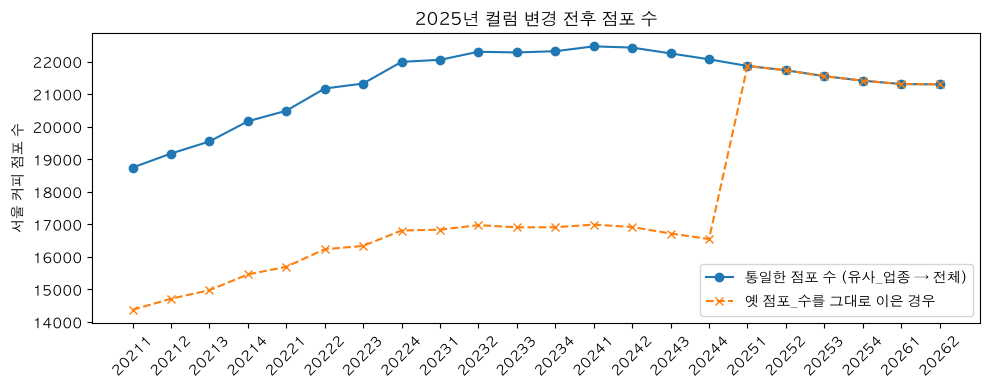

In [6]:
# 서울 전체 커피 점포 수 (관광특구 뺀 값)
seoul = df.groupby('기준_년분기_코드')['점포_수'].sum()

# 비교용: 옛날 점포_수를 그대로 이어 붙였으면 어땠을지
wrong_sql = '''
SELECT 기준_년분기_코드,
       SUM(CASE WHEN 기준_년분기_코드 >= 20251 THEN 전체_점포_수 ELSE 점포_수 END) AS 잘못_이은_점포_수
FROM 원본_점포 p
JOIN 원본_영역 a ON p.상권_코드 = a.상권_코드
WHERE 서비스_업종_코드_명 = '커피-음료' AND a.상권_구분_코드_명 <> '관광특구'
GROUP BY 기준_년분기_코드
ORDER BY 기준_년분기_코드
'''
wrong = pd.read_sql(wrong_sql, engine).set_index('기준_년분기_코드')['잘못_이은_점포_수']

labels = [str(q) for q in seoul.index]
plt.figure(figsize=(10, 4))
plt.plot(labels, seoul.values, marker='o', label='통일한 점포 수 (유사_업종 → 전체)')
plt.plot(labels, wrong.values, marker='x', linestyle='--', label='옛 점포_수를 그대로 이은 경우')
plt.xticks(rotation=45)
plt.ylabel('서울 커피 점포 수')
plt.title('2025년 컬럼 변경 전후 점포 수')
plt.legend()
plt.tight_layout()
plt.show()

통일한 점포 수는 2024년 4분기 22,069개에서 2025년 1분기 21,864개로 끊김 없이 이어집니다. 옛 `점포_수`를 그대로 이었다면 같은 구간에서 16,549개가 21,864개로 바뀌어 한 분기 만에 5,315개가 늘어난 것처럼 보였을 겁니다.

## 2. 매출이 비공개되는 기준

점포 수별로 매출이 있는 비율을 봅니다. 3개 미만에서 0%면 "3개 미만 비공개"가 맞습니다.

In [7]:
# 분석 테이블은 점포 0개를 이미 뺐으니 원본 점포 테이블 기준으로 봄
disclosure_sql = '''
WITH p AS (
    SELECT 기준_년분기_코드, 상권_코드,
           CASE WHEN 기준_년분기_코드 >= 20251 THEN 전체_점포_수 ELSE 유사_업종_점포_수 END AS 점포_수
    FROM 원본_점포
    WHERE 서비스_업종_코드_명 = '커피-음료'
)
SELECT
    LEAST(p.점포_수, 6)::int AS 점포_수_구간,   -- 6은 "6개 이상"
    COUNT(*) AS 상권분기_수,
    ROUND(AVG(CASE WHEN s.당월_매출_금액 IS NOT NULL THEN 1.0 ELSE 0 END), 3) AS 매출_공개_비율
FROM p
LEFT JOIN 원본_추정매출 s
    ON p.상권_코드 = s.상권_코드
   AND p.기준_년분기_코드 = s.기준_년분기_코드
   AND s.서비스_업종_코드_명 = '커피-음료'
GROUP BY LEAST(p.점포_수, 6)
ORDER BY 점포_수_구간
'''
pd.read_sql(disclosure_sql, engine)

,점포_수_구간,상권분기_수,매출_공개_비율
0,0,87,0.000
1,1,3236,0.000
2,2,3041,0.000
3,3,2949,0.638
4,4,2306,0.720
5,5,2158,0.757
6,6,19486,0.951


점포가 0~2개인 상권은 매출이 한 번도 공개되지 않았습니다. 3개부터 공개되기 시작해서(63.8%) 6개 이상이면 95.1%가 공개됩니다. 점포 3개 미만은 비공개라는 기준이 맞습니다. 3개 이상인데 빠진 경우도 있어서 매출 결측은 채우지 않고 그대로 둡니다.

## 3. 결측

In [8]:
# 컬럼별 결측 비율 (0보다 큰 것만)
na_rate = df.isna().mean().sort_values(ascending=False)
na_rate[na_rate > 0].round(3)

점포당_매출_성장률    0.434
주중_매출         0.287
주중_비중         0.287
오전점심_비중       0.287
점포당_매출        0.287
오전점심_매출       0.287
매출            0.287
매출_건수         0.287
상주인구          0.007
직장인구          0.005
유동인구          0.000
오전점심_유동인구     0.000
dtype: float64

In [9]:
# 매출이 있는 줄만 놓고 다시 보기 (실제 분석에 쓰는 줄)
has_sales = df[df['매출'].notna()]
na_rate2 = has_sales.isna().mean().sort_values(ascending=False)
na_rate2[na_rate2 > 0].round(3)

점포당_매출_성장률    0.206
상주인구          0.005
직장인구          0.002
유동인구          0.001
오전점심_유동인구     0.001
dtype: float64

매출 관련 컬럼이 28.7% 비어 있는 건 모두 위의 매출 비공개 때문입니다. 매출이 있는 줄만 보면 성장률 말고는 결측이 1% 미만입니다.

성장률 결측(20.6%) 가운데 4,219줄은 2021년이라 1년 전 값이 원래 없는 경우입니다. 나머지 633줄은 2022년 이후인데 1년 전 매출이 비공개였던 경우입니다. 직장인구와 상주인구가 빈 줄은 원본 파일에 그 상권이 아예 없는 경우입니다(직장인구 1,643개, 상주인구 1,637개 상권).

## 4. 점포당 매출 분포와 이상치

기준 시점인 2026년 2분기만 봅니다. 금액은 분기 매출이고 단위는 원입니다.

In [10]:
latest = df[(df['기준_년분기_코드'] == 20262) & (df['매출'].notna())].copy()
print('2026Q2 분석 대상 상권:', len(latest))

# 보기 편하게 만 원 단위 컬럼을 하나 만듦
latest['점포당_매출_만원'] = latest['점포당_매출'] / 10000
latest['점포당_매출_만원'].describe().round(1)

2026Q2 분석 대상 상권: 1058


count     1058.0
mean      2307.0
std       2595.5
min          3.4
25%        648.9
50%       1482.7
75%       3047.7
max      33632.3
Name: 점포당_매출_만원, dtype: float64

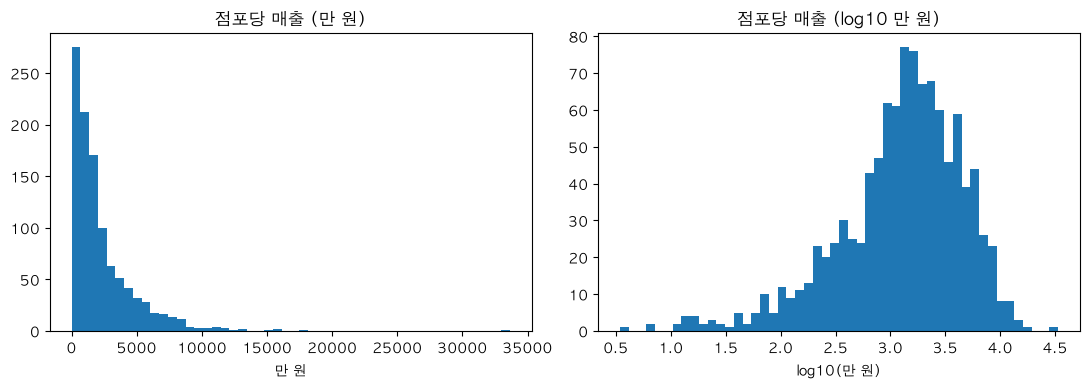

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(latest['점포당_매출_만원'], bins=50)
axes[0].set_title('점포당 매출 (만 원)')
axes[0].set_xlabel('만 원')

# 오른쪽으로 꼬리가 길어서 로그로도 봄
axes[1].hist(np.log10(latest['점포당_매출_만원']), bins=50)
axes[1].set_title('점포당 매출 (log10 만 원)')
axes[1].set_xlabel('log10(만 원)')

plt.tight_layout()
plt.show()

점포당 매출은 오른쪽 꼬리가 긴 분포입니다. 평균(2,307만 원)이 중앙값(1,483만 원)보다 꽤 큽니다. 로그를 취하면 종 모양에 가까워지지만 왼쪽에 아주 작은 값들이 꼬리처럼 남습니다. 4단계 회귀분석에서는 로그 변환한 값을 쓰는 걸 검토합니다.

In [12]:
# 점포당 매출 상위 10개 상권. 이상한 값인지 이름 보고 판단
cols = ['상권_코드_명', '상권_유형', '자치구', '점포_수', '매출', '점포당_매출_만원', '직장인구', '유동인구']
latest.sort_values('점포당_매출', ascending=False)[cols].head(10)

,상권_코드_명,상권_유형,자치구,점포_수,매출,점포당_매출_만원,직장인구,유동인구
22779,시청역_8번,발달상권,중구,38,1.278027e+10,33632.302213,20839.0,406497.0
25881,방배동카페골목,발달상권,서초구,20,3.581524e+09,17907.619025,7381.0,662678.0
3724,광나루역 1번,골목상권,광진구,9,1.404738e+09,15608.195422,1004.0,403911.0
6161,성신여대입구역 4번,골목상권,성북구,10,1.547939e+09,15479.385650,624.0,881876.0
11728,KB국민은행 서강지점,골목상권,마포구,4,6.059924e+08,15149.809725,429.0,215315.0
21859,강동성심병원,골목상권,강동구,4,5.251815e+08,13129.537600,1023.0,130680.0
19504,국기원,골목상권,강남구,11,1.441585e+09,13105.317191,645.0,538860.0
24165,공릉역,발달상권,노원구,16,1.974332e+09,12339.573550,1133.0,514628.0
27553,방이역,발달상권,송파구,17,1.988280e+09,11695.765971,1298.0,374617.0
27399,가락시장,발달상권,송파구,8,9.315460e+08,11644.324538,5755.0,30101.0


In [13]:
# 반대로 하위 10개
latest.sort_values('점포당_매출')[cols].head(10)

,상권_코드_명,상권_유형,자치구,점포_수,매출,점포당_매출_만원,직장인구,유동인구
20950,경찰병원역 4번(건너말공원),골목상권,송파구,6,206602.0,3.443367,564.0,337966.0
17885,당곡중학교,골목상권,관악구,14,902981.0,6.449864,281.0,911528.0
28917,뚝도시장,전통시장,성동구,7,465842.0,6.654886,477.0,389646.0
14394,개웅초등학교(개웅중학교),골목상권,구로구,4,462819.0,11.570475,273.0,614428.0
6733,장곡초등학교,골목상권,성북구,5,614254.0,12.285080,166.0,933327.0
5875,성북초등학교앞,골목상권,성북구,9,1181399.0,13.126656,890.0,165333.0
17085,상도역 2번,골목상권,동작구,9,1196361.0,13.292900,169.0,563856.0
607,동대문역 1번,골목상권,종로구,9,1213469.0,13.482989,45.0,2307516.0
31587,남구로시장,전통시장,구로구,5,740075.0,14.801500,290.0,734868.0
19023,남부터미널역 1번,골목상권,서초구,9,1348981.0,14.988678,4151.0,1517589.0


상위 1위 시청역_8번은 점포당 분기 매출이 3억 3,600만 원으로 2위의 두 배 가까이 됩니다. 직장인구가 2만 명이 넘는 도심 오피스 상권이라 매출이 큰 건 이해가 가지만 다른 상권과 차이가 커서 4단계에서 이 상권 하나가 결과를 좌우하지 않는지 확인하겠습니다. 나머지 상위 상권은 역 출구, 카페거리, 병원 앞이라 실제 상권으로 봐도 무리가 없습니다.

하위권에는 믿기 어려운 값이 있습니다. 경찰병원역 4번은 점포 6개의 분기 매출이 20만 원입니다. 점포당 분기 매출이 100만 원도 안 되는 상권이 2026년 2분기에만 53곳입니다. 카드 매출 추정치라 실제보다 크게 낮게 잡힌 것으로 보입니다. 3단계 규칙대로 지우지는 않았고, 이 상권들을 어떻게 다룰지는 4단계를 시작할 때 정하겠습니다.

In [14]:
# 상권 유형별 차이
latest.groupby('상권_유형').agg(
    상권_수=('상권_코드', 'count'),
    점포당_매출_중앙값_만원=('점포당_매출_만원', 'median'),
    점포_수_중앙값=('점포_수', 'median'),
    오전점심_비중_중앙값=('오전점심_비중', 'median'),
    주중_비중_중앙값=('주중_비중', 'median'),
).round(2)

,상권_수,점포당_매출_중앙값_만원,점포_수_중앙값,오전점심_비중_중앙값,주중_비중_중앙값
상권_유형,,,,,
골목상권,687,1062.48,9.0,0.50,0.68
발달상권,244,3656.78,29.5,0.51,0.72
전통시장,127,1750.62,7.0,0.46,0.67


발달상권의 점포당 매출 중앙값(3,657만 원)이 골목상권(1,062만 원)의 세 배가 넘습니다. 오전·점심 비중(46~51%)과 주중 비중(67~72%)은 유형별 차이가 크지 않습니다.

## 5. 성장률 계산 확인

SQL에서 LAG로 구한 성장률이 손으로 계산한 값과 같은지 상권 하나로 확인합니다.

In [15]:
# 2026Q2와 2025Q2 둘 다 매출이 있는 상권 중 첫 번째
sample_code = latest[latest['점포당_매출_성장률'].notna()]['상권_코드'].iloc[0]
sample = df[df['상권_코드'] == sample_code].set_index('기준_년분기_코드')

now = sample.loc[20262, '점포당_매출']
before = sample.loc[20252, '점포당_매출']
print(sample.loc[20262, '상권_코드_명'])
print('손으로 계산:', round(now / before - 1, 4))
print('SQL 값    :', round(sample.loc[20262, '점포당_매출_성장률'], 4))

독립문역 1번
손으로 계산: 0.467
SQL 값    : 0.467


In [16]:
# 성장률이 비어 있는 이유가 "1년 전 매출이 없어서"인지 확인
no_growth = latest[latest['점포당_매출_성장률'].isna()]
print('2026Q2 성장률 없는 상권:', len(no_growth))

last_year = df[df['기준_년분기_코드'] == 20252].set_index('상권_코드')['매출']
print('그중 2025Q2 매출이 없는 상권 (줄 자체가 없는 경우 포함):', no_growth['상권_코드'].map(last_year).isna().sum())

2026Q2 성장률 없는 상권: 23
그중 2025Q2 매출이 없는 상권 (줄 자체가 없는 경우 포함): 23


독립문역 1번으로 확인해 보니 손으로 계산한 값과 SQL 값이 0.467로 같습니다. 2026년 2분기에 성장률이 없는 23곳은 모두 1년 전 매출이 없는 상권이라 계산 방식의 문제는 아닙니다.

## 정리

| 정제 규칙 | 결과 |
|---|---|
| 점포 수 통일 | 식이 안 맞는 행 0개, 2025년 1분기에 끊김 없음 |
| 매출 단위 | 분기 매출로 표기 |
| 매출 비공개 | 점포 0~2개는 공개 0%, 결측은 채우지 않음 |
| 집객시설 빈 값 | 0으로 바꿈 |
| 관광특구 | 제외 |
| 이상치 | 지우지 않음, 상위·하위 상권 이름으로 확인 |
| 성장률 | LAG로 계산, 손 계산과 같음 |

2026년 2분기 기준 분석 대상은 1,058개 상권입니다.

4단계로 넘기는 것
- 점포당 분기 매출이 100만 원 미만인 상권 53곳을 어떻게 다룰지
- 시청역_8번 하나가 회귀 결과를 좌우하지 않는지
- 점포당 매출을 로그 변환해서 쓸지